# Activité pratique n°2 — Modèles génératifs

**Nom :** Mohamed Ouallal  
**Classe :** IADATA — Groupe 4  
**Enseignant :** Mohamed YOUSSFI

## 0. Configuration de l’environnement


In [1]:
import sys
import torch
import torchvision
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torcheval
from torcheval.metrics import MulticlassAccuracy

assert sys.version_info[:2] == (3, 11), "Sélectionner l’environnement Python 3.11 du projet."
assert sys.prefix != sys.base_prefix, "Sélectionner l’environnement virtuel du projet."

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python :", sys.version.split()[0])
print("Environnement virtuel :", sys.prefix)
print("PyTorch :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Matplotlib :", matplotlib.__version__)
print("NumPy :", np.__version__)
print("Torcheval :", torcheval.__version__)
print("Appareil :", device)


Matplotlib is building the font cache; this may take a moment.


Python : 3.11.18
Environnement virtuel : /Users/mohamedouallal/emsi/5IIR/IAGEN/partie2/.venv
PyTorch : 2.15.0
Torchvision : 0.29.2
Matplotlib : 3.11.2
NumPy : 2.4.6
Torcheval : 0.0.7
Appareil : cpu


/Users/mohamedouallal/emsi/5IIR/IAGEN/partie2/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. Chargement du dataset MNIST



In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("Images d'entraînement :", len(train_dataset))
print("Images de test :", len(test_dataset))
print("Classes :", train_dataset.classes)


Images d’entraînement : 60000
Images de test : 10000
Classes : ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']


Dimensions des images : torch.Size([128, 1, 28, 28])
Dimensions des étiquettes : torch.Size([128])
Type des images : torch.float32
Type des étiquettes : torch.int64
Valeurs des pixels : [0.0, 1.0]


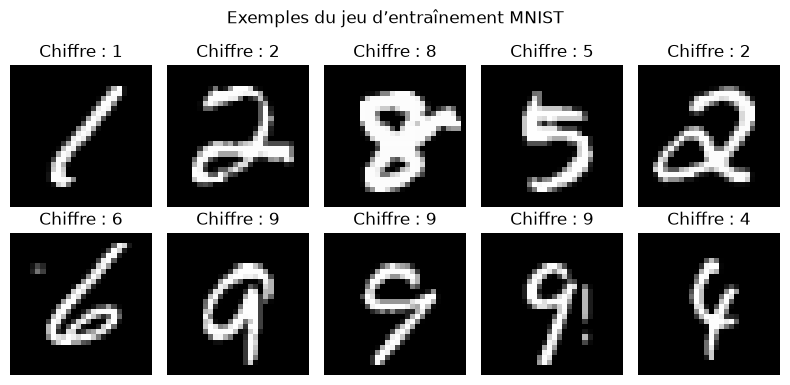

In [3]:
images, labels = next(iter(train_loader))

print("Dimensions des images :", images.shape)
print("Dimensions des étiquettes :", labels.shape)
print("Type des images :", images.dtype)
print("Type des étiquettes :", labels.dtype)
print(f"Valeurs des pixels : [{images.min().item():.1f}, {images.max().item():.1f}]")

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Chiffre : {labels[i].item()}")
    ax.axis("off")
plt.suptitle("Exemples du jeu d’entraînement MNIST")
plt.tight_layout()
plt.show()


## 2. Modèle discriminatif


In [4]:
from torch import nn

torch.manual_seed(42)

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)
print(classifier)


Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


### Entraînement


Époque 1/3 | Perte : 0.4100


Époque 2/3 | Perte : 0.1925


Époque 3/3 | Perte : 0.1420


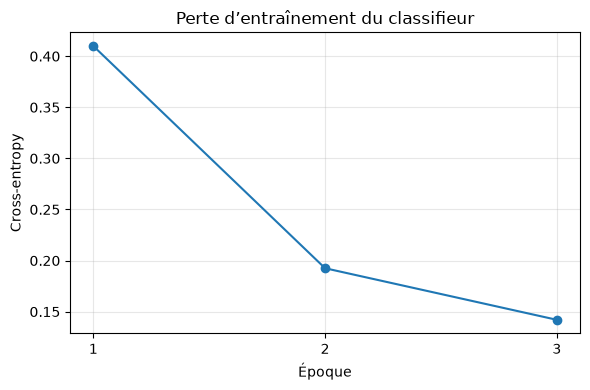

In [5]:
epochs = 3
classifier_losses = []

for epoch in range(epochs):
    classifier.train()
    total_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = classifier(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    classifier_losses.append(average_loss)
    print(f"Époque {epoch + 1}/{epochs} | Perte : {average_loss:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs + 1), classifier_losses, marker="o")
plt.xticks(range(1, epochs + 1))
plt.xlabel("Époque")
plt.ylabel("Cross-entropy")
plt.title("Perte d’entraînement du classifieur")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Évaluation sur le jeu de test


Perte sur le test : 0.1275
Accuracy sur le test : 96.23%
Images bien classées : 9623/10000


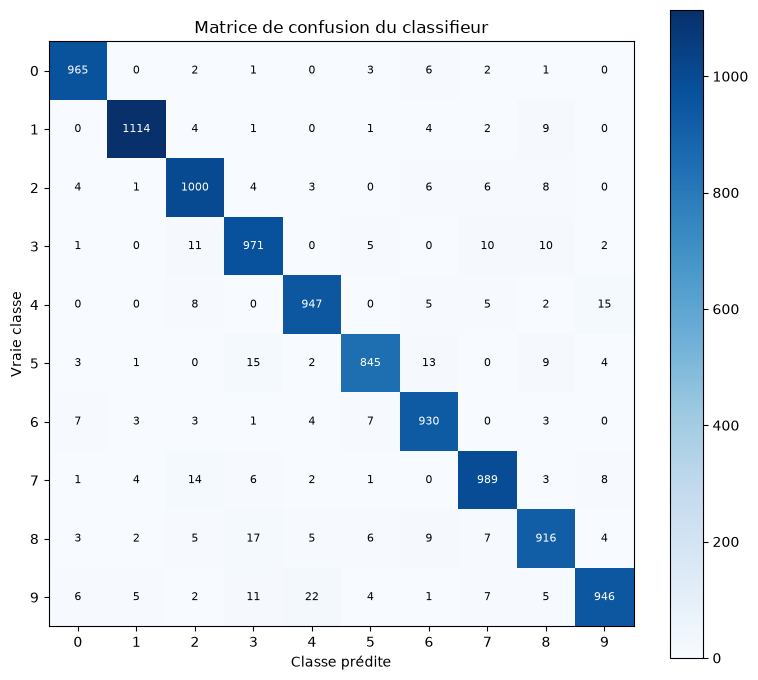

In [6]:
classifier.eval()
metric = MulticlassAccuracy(num_classes=10, device=device)
test_loss = 0.0
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        logits = classifier(images)
        test_loss += criterion(logits, labels).item() * images.size(0)
        metric.update(logits, labels)
        all_predictions.append(logits.argmax(dim=1).cpu())
        all_labels.append(labels.cpu())

classifier_predictions = torch.cat(all_predictions)
classifier_labels = torch.cat(all_labels)
accuracy = metric.compute().item()
correct = (classifier_predictions == classifier_labels).sum().item()

print(f"Perte sur le test : {test_loss / len(test_dataset):.4f}")
print(f"Accuracy sur le test : {accuracy:.2%}")
print(f"Images bien classées : {correct}/{len(test_dataset)}")

# Les lignes correspondent aux vraies classes et les colonnes aux prédictions.
confusion = torch.bincount(
    classifier_labels * 10 + classifier_predictions, minlength=100
).reshape(10, 10)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(confusion.numpy(), cmap="Blues")
for i in range(10):
    for j in range(10):
        value = confusion[i, j].item()
        ax.text(j, i, str(value), ha="center", va="center",
                color="white" if value > confusion.max().item() / 2 else "black",
                fontsize=8)
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("Classe prédite")
ax.set_ylabel("Vraie classe")
ax.set_title("Matrice de confusion du classifieur")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


Images mal classées : 377


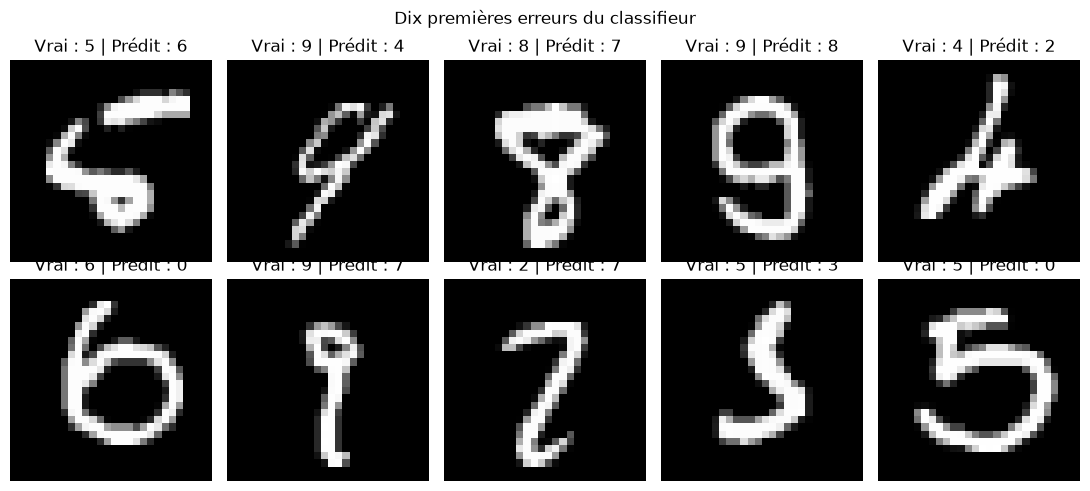

In [7]:
error_indices = (classifier_predictions != classifier_labels).nonzero(as_tuple=True)[0]
print(f"Images mal classées : {len(error_indices)}")

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax in axes.flat:
    ax.axis("off")
for ax, index in zip(axes.flat, error_indices[:10].tolist()):
    image, label = test_dataset[index]
    ax.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Vrai : {label} | Prédit : {classifier_predictions[index].item()}")
plt.suptitle("Dix premières erreurs du classifieur")
plt.tight_layout()
plt.show()
